# Option 2: Logistic Regression
## Step 0: Import Libraries & Load Data

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 27

In [4]:
data_path = "../cornell-tech-cs-5785-combined-2026-ai-vs-human-text"
train_df = pd.read_csv(f"{data_path}/train.csv")
test_df = pd.read_csv(f"{data_path}/test.csv")

## Step 1: Split the Training Data

In [5]:
from sklearn.model_selection import train_test_split

X = train_df.drop(columns=["label"])
y = train_df["label"]
X_train, X_dev, y_train, y_dev = train_test_split(X, y, test_size=2000, random_state=RANDOM_STATE, stratify=y)
X_dev[["id"]].to_csv("val_ids.csv", index=False)
print(len(X_train), len(X_dev))

8000 2000


In [ ]:
# Sample a few examples of each class to see what the data looks like
for label in [0, 1]:
    print(f"===== label {label} ({'AI' if label else 'human'}) =====")
    for t in X_train[y_train == label]["text"].sample(3, random_state=RANDOM_STATE):
        print(t[:400], "\n")

===== label 0 (human) =====
We present highly efficient algorithms for performing forward and backward
propagation of Convolutional Neural Network (CNN) for pixelwise classification
on images. For pixelwise classification tasks, such as image segmentation and
object detection, surrounding image patches are fed into CNN for predicting the
classes of centered pixels via forward propagation and for updating CNN
parameters via b 

Provideo (4 January 1982 – 7 September 2000) was an Irish Thoroughbred racehorse and sire. In 1984 he set a 20th-century record for a British-trained two-year-old when he won sixteen of his twenty-four races. His most important wins were in two Listed races, the Star Stakes at Sandown Park and the Champion Two-Year-Old Trophy at Ripon Racecourse. Despite being rated twenty pounds below the best ho 

Oil prices retreated from four-month highs in early trading on Tuesday after producers' cartel Opec said it was now unlikely to cut production.
Following the comments

## Step 2: Preprocess Data

In [16]:
import re
import string

import nltk
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

nltk.download("punkt_tab")

# Regex rules that collapse noisy, high-variety strings into one shared token,
# so e.g. every file path counts as a single feature instead of thousands of rare ones.
# Order matters: specific patterns run first (UUIDs before generic hex hashes,
# decimals before integers) so a shorter rule doesn't break up a longer match.
PLACEHOLDERS = [
    (re.compile(r"(?<!\w)(?:~|\.\.?)?/[\w.\-]+(?:/[\w.\-]+)*|\b[\w.\-]+(?:/[\w.\-]+){2,}"), " pathtoken "),
    (re.compile(r"\b[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}\b", re.IGNORECASE), " hashtoken "),
    (re.compile(r"\b[0-9a-f]{16,}\b", re.IGNORECASE), " hashtoken "),
    (re.compile(r"\b\d+\.\d+\b"), " decimaltoken "),
    (re.compile(r"\b\d{4,}\b"), " bignumtoken "),
    (re.compile(r"\b\d{1,3}\b"), " smallnumtoken "),
]

ps = PorterStemmer()

def replacePlaceholders(s):
    """
    Replace file paths, hashes, and numbers with shared placeholder tokens.

    Parameters:
    - s: str, raw passage text.

    Returns:
    - s: str, text with each match of a PLACEHOLDERS rule replaced by its token
      (e.g. "3.14" -> "decimaltoken", "42" -> "smallnumtoken").
    """
    for pattern, token in PLACEHOLDERS:
        s = pattern.sub(token, s)

    return s

def stem(s):
    """
    Reduce each word to its Porter stem by chopping common suffixes.

    Parameters:
    - s: str, text to stem.

    Returns:
    - str, space-joined stemmed words (e.g. "running" -> "run",
      "studies" -> "studi"; "better" stays "better").
    """
    words = word_tokenize(s)
    stemmed = [ps.stem(word) for word in words]
    return " ".join(stemmed)

def stripPunctuation(s):
    """
    Delete apostrophes and replace all other punctuation with spaces.

    Parameters:
    - s: str, text to clean.

    Returns:
    - clean_text: str, text with apostrophes (' and ’) removed ("don't" -> "dont"),
      and all other punctuation, including curly quotes and em/en dashes,
      turned into spaces. Underscores are kept.
    """
    punct = string.punctuation.replace("_", "").replace("'", "") + "‘“”—–"
    PUNCT_TO_SPACE = str.maketrans(punct, " " * len(punct))
    APOSTROPHIES = str.maketrans("", "", "'’")

    clean_text = s.translate(APOSTROPHIES).translate(PUNCT_TO_SPACE)
    return clean_text

def preprocess(text):
    """
    Apply the full cleaning pipeline to one passage before vectorizing.
    Placeholders run first because the path and decimal rules need
    '/' and '.', which stripPunctuation removes.

    Parameters:
    - text: str, raw passage text.

    Returns:
    - text: str, cleaned text (placeholders -> lowercase -> no punctuation -> stemmed).
    """
    text = replacePlaceholders(text)    # Step 1 - Replace placeholders
    text = text.lower() # Step 2 - Lowercase
    text = stripPunctuation(text)   # Step 3.2 - Strip punctuation
    text = stem(text)  # Step 4 - Stem each word of the text
    return text

[nltk_data] Downloading package punkt_tab to /Users/henry/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [9]:
train_clean = X_train.copy()
train_clean["text"] = train_clean["text"].apply(preprocess)

dev_clean = X_dev.copy()
dev_clean["text"] = dev_clean["text"].apply(preprocess)

## Step 3: Vectorize Data

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

M = 2
vectorizer = TfidfVectorizer(min_df=M, ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(train_clean["text"])  # learn vocabulary + IDF from training text only
X_dev_tfidf = vectorizer.transform(dev_clean["text"])          # reuse them on validation
print(X_train_tfidf.shape, X_dev_tfidf.shape)

(8000, 154431) (2000, 154431)


## Step 4: Logistic Regression

### Evaluate Functions

In [22]:
# Import logistic regression model from sklearn
import time

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def evaluate(model, X_tra, y_tra, X_va, y_va):
    """
    Fit a logistic regression model and evaluate its performance on training and validation sets.

    Parameters:
    - model: sklearn LogisticRegression instance.
    - X_tr, y_tr: training features and labels.
    - X_va, y_va: validation features and labels.

    Returns:
    - res: dictionary, containing training AUROC, validation AUROC, and training time.
    """
    start = time.perf_counter()
    model.fit(X_tra, y_tra)
    train_time = time.perf_counter() - start

    train_auroc = roc_auc_score(y_tra, model.predict_proba(X_tra)[:, 1])
    val_auroc = roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])
    print(f"Train AUROC: {train_auroc:.4f} | Val AUROC: {val_auroc:.4f} | Time: {train_time:.1f}s")
    res = {"train_auroc": train_auroc, "val_auroc": val_auroc, "train_time": train_time}
    return res

def run_c_grid(penalty, X_tr, y_tr, X_va, y_va, C_values):
    """
    Train L1 and L2 logistic regression at each C value and collect the results.

    Parameters:
    - penalty: str, either "L1" or "L2" to specify the regularization type.
    - X_tr, y_tr: training features and labels.
    - X_va, y_va: validation features and labels.
    - C_values: iterable of floats, C values to try (inverse regularization strength).

    Returns:
    - results_df: pd.DataFrame, one row per (penalty, C) with train/validation
      AUROC, train time, and the number of nonzero weights.
    """
    results = []
    for C in C_values:
        if penalty == "L1":
            model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                        l1_ratio=1.0, solver="liblinear", C=C)
        else:
            model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                        l1_ratio=0, C=C)

        print(f"{penalty}, C={C:g}: ", end="")
        res = evaluate(model, X_tr, y_tr, X_va, y_va)
        res.update({"penalty": penalty, "C": C,
                    "nonzero_weights": int((model.coef_ != 0).sum())})
        results.append(res)

    return pd.DataFrame(results)


C_values = np.logspace(-2, 3, 6)  # 0.01, 0.1, 1, 10, 100, 1000


### No Regularization Model

In [12]:
model_noreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, C=np.inf)
noreg_res = evaluate(model_noreg, X_train_tfidf, y_train, X_dev_tfidf, y_dev)


Train AUROC: 1.0000 | Val AUROC: 0.9385 | Time: 0.6s


### L1 Regularization Model

In [24]:
l1_grid = run_c_grid("L1", X_train_tfidf, y_train, X_dev_tfidf, y_dev, C_values)
l1_grid

L1, C=0.01: Train AUROC: 0.5000 | Val AUROC: 0.5000 | Time: 0.0s
L1, C=0.1: Train AUROC: 0.6751 | Val AUROC: 0.6899 | Time: 0.1s
L1, C=1: Train AUROC: 0.9233 | Val AUROC: 0.9014 | Time: 0.7s
L1, C=10: Train AUROC: 0.9999 | Val AUROC: 0.9306 | Time: 1.7s
L1, C=100: Train AUROC: 1.0000 | Val AUROC: 0.9240 | Time: 1.4s
L1, C=1000: Train AUROC: 1.0000 | Val AUROC: 0.9268 | Time: 0.4s


,train_auroc,val_auroc,train_time,penalty,C,nonzero_weights
0,0.500000,0.500000,0.028135,L1,0.01,0
1,0.675136,0.689942,0.122841,L1,0.10,2
2,0.923292,0.901387,0.659302,L1,1.00,223
3,0.999941,0.930627,1.703540,L1,10.00,2068
4,1.000000,0.924011,1.422267,L1,100.00,2773
5,1.000000,0.926758,0.359644,L1,1000.00,4850


### L2 Regularization Model

In [25]:
l2_grid = run_c_grid("L2", X_train_tfidf, y_train, X_dev_tfidf, y_dev, C_values)
l2_grid

L2, C=0.01: Train AUROC: 0.9367 | Val AUROC: 0.8776 | Time: 0.0s
L2, C=0.1: Train AUROC: 0.9608 | Val AUROC: 0.8968 | Time: 0.1s
L2, C=1: Train AUROC: 0.9952 | Val AUROC: 0.9245 | Time: 0.2s
L2, C=10: Train AUROC: 1.0000 | Val AUROC: 0.9379 | Time: 0.4s
L2, C=100: Train AUROC: 1.0000 | Val AUROC: 0.9413 | Time: 0.3s
L2, C=1000: Train AUROC: 1.0000 | Val AUROC: 0.9382 | Time: 0.2s


,train_auroc,val_auroc,train_time,penalty,C,nonzero_weights
0,0.936749,0.877625,0.041528,L2,0.01,154431
1,0.960829,0.896819,0.072190,L2,0.10,154431
2,0.995228,0.924457,0.236900,L2,1.00,154431
3,1.000000,0.937911,0.358276,L2,10.00,154431
4,1.000000,0.941263,0.303124,L2,100.00,154431
5,1.000000,0.938217,0.224272,L2,1000.00,154431


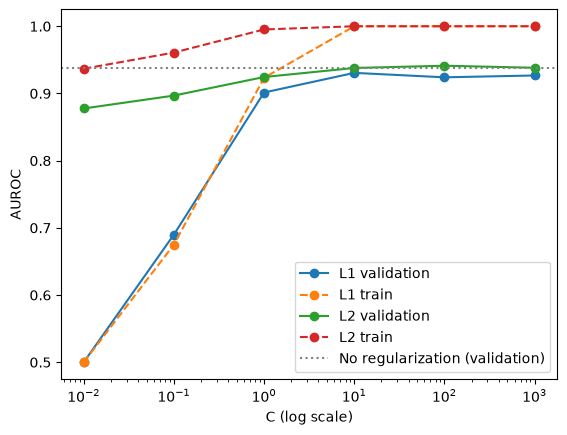

In [28]:
grid_df = {
    "L1": l1_grid,
    "L2": l2_grid
}

for penalty in ["L1", "L2"]:
    sub = grid_df[penalty]
    plt.plot(sub["C"], sub["val_auroc"], marker="o", label=f"{penalty} validation")
    plt.plot(sub["C"], sub["train_auroc"], marker="o", linestyle="--", label=f"{penalty} train")

plt.axhline(noreg_res["val_auroc"], color="gray", linestyle=":", label="No regularization (validation)")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("AUROC")
plt.legend()
plt.show()

### Naive Bayes

In [29]:
from sklearn.naive_bayes import MultinomialNB


def run_alpha_grid(X_tr, y_tr, X_va, y_va, alpha_values):
    """
    Train Multinomial Naive Bayes at each smoothing value alpha and collect the results.

    Parameters:
    - X_tr, y_tr: training features and labels.
    - X_va, y_va: validation features and labels.
    - alpha_values: iterable of floats, smoothing pseudo-counts to try.

    Returns:
    - results_df: pd.DataFrame, one row per alpha with train/validation AUROC and train time.
    """
    results = []
    for alpha in alpha_values:
        model = MultinomialNB(alpha=alpha)
        print(f"alpha={alpha:g}: ", end="")
        res = evaluate(model, X_tr, y_tr, X_va, y_va)
        res["alpha"] = alpha
        results.append(res)
    return pd.DataFrame(results)


alpha_values = np.logspace(-3, 1, 5)  # 0.001, 0.01, 0.1, 1, 10
nb_df = run_alpha_grid(X_train_tfidf, y_train, X_dev_tfidf, y_dev, alpha_values)
nb_df

alpha=0.001: Train AUROC: 1.0000 | Val AUROC: 0.8690 | Time: 0.0s
alpha=0.01: Train AUROC: 1.0000 | Val AUROC: 0.8790 | Time: 0.0s
alpha=0.1: Train AUROC: 0.9994 | Val AUROC: 0.8884 | Time: 0.0s
alpha=1: Train AUROC: 0.9912 | Val AUROC: 0.8915 | Time: 0.0s
alpha=10: Train AUROC: 0.9612 | Val AUROC: 0.8826 | Time: 0.0s


,train_auroc,val_auroc,train_time,alpha
0,0.999997,0.869020,0.017237,0.001
1,0.999962,0.878991,0.007584,0.010
2,0.999383,0.888397,0.006599,0.100
3,0.991246,0.891510,0.007274,1.000
4,0.961250,0.882643,0.006863,10.000
